<a href="https://colab.research.google.com/github/ismaelmarcosp2-dev/Unidades-praticas/blob/main/Atividade_pratica_U3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sqlite3

# Conectar ao banco de dados SQLite
conexao = sqlite3.connect('dados_vendas.db')

# Criar um cursor para executar os comandos SQL
cursor = conexao.cursor()

# Criar a tabela de vendas
cursor.execute('''
CREATE TABLE IF NOT EXISTS vendas1 (
    id_venda INTEGER PRIMARY KEY AUTOINCREMENT,
    data_venda DATE,
    produto TEXT,
    categoria TEXT,
    valor_venda REAL
)
''')

# Confirmar as alterações
conexao.commit()

print("Banco de dados e tabela criados com sucesso!")


Banco de dados e tabela criados com sucesso!


In [ ]:
# Inserir os dados das vendas
cursor.execute('''
INSERT INTO vendas1 (data_venda, produto, categoria, valor_venda) VALUES
('2023-01-01', 'Produto A', 'Eletrônicos', 1500.00),
('2023-01-05', 'Produto B', 'Roupas', 350.00),
('2023-02-10', 'Produto C', 'Eletrônicos', 1200.00),
('2023-03-15', 'Produto D', 'Livros', 200.00),
('2023-03-20', 'Produto E', 'Eletrônicos', 800.00),
('2023-04-02', 'Produto F', 'Roupas', 400.00),
('2023-05-05', 'Produto G', 'Livros', 150.00),
('2023-06-10', 'Produto H', 'Eletrônicos', 1000.00),
('2023-07-20', 'Produto I', 'Roupas', 600.00),
('2023-08-25', 'Produto J', 'Eletrônicos', 700.00),
('2023-09-30', 'Produto K', 'Livros', 300.00),
('2023-10-05', 'Produto L', 'Roupas', 450.00),
('2023-11-15', 'Produto M', 'Eletrônicos', 900.00),
('2023-12-20', 'Produto N', 'Livros', 250.00)
''')

# Confirmar a inserção dos dados
conexao.commit()

print("Dados inseridos com sucesso!")


Dados inseridos com sucesso!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Carregar os dados da tabela para um DataFrame
df_vendas = pd.read_sql_query("SELECT * FROM vendas1", conexao)

# Exibir os dados
df_vendas


,id_venda,data_venda,produto,categoria,valor_venda
0,1,2023-01-01,Produto A,Eletrônicos,1500.0
1,2,2023-01-05,Produto B,Roupas,350.0
2,3,2023-02-10,Produto C,Eletrônicos,1200.0
3,4,2023-03-15,Produto D,Livros,200.0
4,5,2023-03-20,Produto E,Eletrônicos,800.0
5,6,2023-04-02,Produto F,Roupas,400.0
6,7,2023-05-05,Produto G,Livros,150.0
7,8,2023-06-10,Produto H,Eletrônicos,1000.0
8,9,2023-07-20,Produto I,Roupas,600.0
9,10,2023-08-25,Produto J,Eletrônicos,700.0


In [ ]:
# Verificar informações do DataFrame
print("Informações dos dados:")
df_vendas.info()

print("\nResumo estatístico:")
display(df_vendas.describe())


Informações dos dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_venda     14 non-null     int64  
 1   data_venda   14 non-null     object 
 2   produto      14 non-null     object 
 3   categoria    14 non-null     object 
 4   valor_venda  14 non-null     float64
dtypes: float64(1), int64(1), object(3)
memory usage: 692.0+ bytes

Resumo estatístico:


,id_venda,valor_venda
count,14.0000,14.000000
mean,7.5000,628.571429
std,4.1833,407.484915
min,1.0000,150.000000
25%,4.2500,312.500000
50%,7.5000,525.000000
75%,10.7500,875.000000
max,14.0000,1500.000000


In [ ]:
# Calcular o total de vendas
total_vendas = df_vendas['valor_venda'].sum()

print(f"Total de vendas: R$ {total_vendas:.2f}")


Total de vendas: R$ 8800.00


In [ ]:
# Calcular a média das vendas
media_vendas = df_vendas['valor_venda'].mean()

print(f"Média das vendas: R$ {media_vendas:.2f}")


Média das vendas: R$ 628.57


In [ ]:
# Total de vendas por categoria
vendas_categoria = df_vendas.groupby('categoria')['valor_venda'].sum()

print(vendas_categoria)


categoria
Eletrônicos    6100.0
Livros          900.0
Roupas         1800.0
Name: valor_venda, dtype: float64


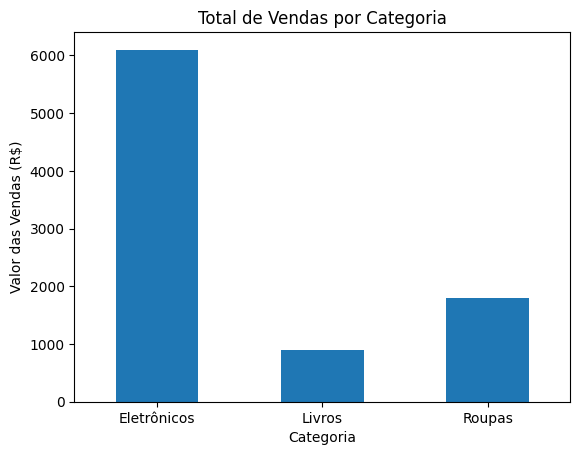

In [ ]:
# Gráfico de vendas por categoria
vendas_categoria.plot(kind='bar')

plt.title('Total de Vendas por Categoria')
plt.xlabel('Categoria')
plt.ylabel('Valor das Vendas (R$)')
plt.xticks(rotation=0)
plt.show()


In [ ]:
# Somar as vendas por mês
vendas_mes = df_vendas.groupby('mes')['valor_venda'].sum()

# Criar o gráfico
plt.figure(figsize=(10, 5))

plt.plot(vendas_mes.index, vendas_mes.values, marker='o')

plt.title('Vendas ao Longo dos Meses')
plt.xlabel('Mês')
plt.ylabel('Valor das Vendas (R$)')
plt.xticks(range(1, 13))

plt.show()

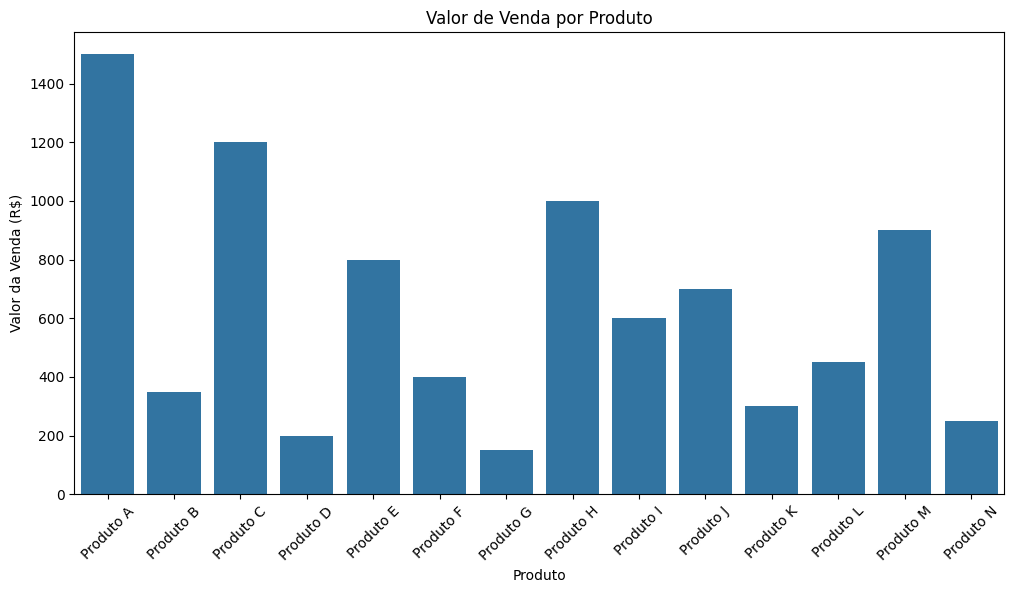

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_vendas,
    x='produto',
    y='valor_venda'
)

plt.title('Valor de Venda por Produto')
plt.xlabel('Produto')
plt.ylabel('Valor da Venda (R$)')
plt.xticks(rotation=45)
plt.show()


In [ ]:
# Encontrar o produto com maior valor de venda
maior_venda = df_vendas.loc[df_vendas['valor_venda'].idxmax()]

print("Produto com maior venda:")
print(maior_venda)


Produto com maior venda:
id_venda                 1
data_venda      2023-01-01
produto          Produto A
categoria      Eletrônicos
valor_venda         1500.0
Name: 0, dtype: object


In [ ]:
# Encontrar a categoria com maior faturamento
categoria_maior_venda = vendas_categoria.idxmax()
valor_maior_categoria = vendas_categoria.max()

print(f"Categoria com maior faturamento: {categoria_maior_venda}")
print(f"Valor total: R$ {valor_maior_categoria:.2f}")


Categoria com maior faturamento: Eletrônicos
Valor total: R$ 6100.00
